# Weather Forecast Error by Sky Condition

**Question:** how wrong is the ECMWF day-ahead irradiance forecast, and does that error depend on whether the sky is clear, broken cloud, or overcast? Answered per rooftop.

This is **not** about PV model error. It isolates the *input*: the gap between forecast sunlight and real sunlight. Everything downstream inherits this error, so it sets the ceiling on any PV model built on top.

## Why this matters here

Every model family tried on this dataset lands at R² 0.79-0.81 (random forest, XGBoost, LightGBM, LSTM, attention-LSTM, TFT, MOS, Kalman). An oracle test showed perfect *regional* weather truth is worth only +0.023 R². That points at the weather input as the binding constraint. This notebook looks directly at that input.

## READ THIS BEFORE QUOTING ANY NUMBER — the ground-truth caveat

`actual_ghi` in `mos_training_data.csv` is **ERA5 reanalysis, not a ground measurement**. ERA5 is itself an ECMWF model product. It shares physics and assimilation machinery with the IFS forecast being scored against it.

**Consequence: the errors below are OPTIMISTIC.** A model compared against its own family's reanalysis agrees better than it would against a real pyranometer. Treat these as a *lower bound* on true forecast error.

Section 8 provides an independent cross-check using the PV panels themselves as irradiance sensors. Where the two disagree, trust the PV-derived view.

## Outputs

- `reports/weather_error/<system_id>.png` — one six-panel figure per rooftop
- `reports/weather_error/summary_by_system_regime.csv` — every metric, per house per regime

In [2]:
pip install pvlib

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/19.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/19.4 MB ? eta -:--:--
   --- ------------------------------------ 1.6/19.4 MB 8.8 MB/s eta 0:00:03
   ---- ----------------------------------- 2.4/19.4 MB 6.1 MB/s eta 0:00:03
   ------ --------------------------------- 3.1/19.4 MB 5.3 MB/s eta 0:00:04
   --------- ------------------------------ 4.7/19.4 MB 6.1 MB/s eta 0:00:03
   ------------ --------------------------- 6.0/19.4 MB 6.1 MB/s eta 0:00:03
   --------------- ------------------------ 7.3/19.4 MB 6.0 MB/s eta 0:00:02
   ----------------- ---------------------- 8.7/19.4 MB 6.1 MB/s eta 0:00:02
   -------------------- ------------------- 10.0/19.4 MB 6.1 MB/s eta 0:00:02
   ----------------------- ---------------- 11.3/19.4 MB 6.2 MB/s eta 0:00:02
   -------------------------- ------------- 12.8/19.4 MB 6.3 MB/s eta 0:00:02
   ------

In [3]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pvlib

warnings.filterwarnings("ignore")

V3 = Path.cwd().parent if Path.cwd().name == "notebooks" else Path("v3_ensemble")
sys.path.insert(0, str(V3))
import config as C

OUT = C.REPORTS_DIR / "weather_error"
OUT.mkdir(parents=True, exist_ok=True)

MOS_FILE = C.PROJECT_ROOT / "data" / "interim" / "mos_training_data.csv"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "font.size": 9,
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
    "axes.spines.right": False, "figure.facecolor": "white",
})
print("v3 root :", V3)
print("outputs :", OUT)

v3 root : f:\solar_forecasting\v3_ensemble
outputs : F:\solar_forecasting\v3_ensemble\reports\weather_error


## 1. Load forecast and "actual" irradiance

One row per system per hour. `ecmwf_ghi` is the day-ahead forecast (`_previous_day1`, published before the noon D-1 cutoff — no leakage). `actual_ghi` is the ERA5 value for the same hour and coordinates.

In [4]:
wx = pd.read_csv(MOS_FILE)
wx["timestamp"] = pd.to_datetime(wx["timestamp"], utc=True)
wx = wx.dropna(subset=["system_id", "actual_ghi", "ecmwf_ghi"])
wx["system_id"] = wx["system_id"].astype(int)
wx = wx[~wx.system_id.isin(C.EXCLUDE_SYSTEMS)]

meta = pd.read_csv(C.PARENT_META).drop_duplicates("system_id")
coords = meta.set_index("system_id")[["latitude", "longitude"]]
wx = wx[wx.system_id.isin(coords.index)]

print(f"rows      : {len(wx):,}")
print(f"systems   : {wx.system_id.nunique()}")
print(f"window    : {wx.timestamp.min():%Y-%m-%d} -> {wx.timestamp.max():%Y-%m-%d}")
wx.head()

rows      : 318,708
systems   : 34
window    : 2024-04-01 -> 2026-05-31


,system_id,timestamp,actual_ghi,actual_cloud,ecmwf_ghi,ecmwf_cloud,ecmwf_temp
0,33949,2024-04-01 07:00:00+00:00,16.0,100,26.0,96,6.2
1,33949,2024-04-01 08:00:00+00:00,37.0,100,60.0,89,6.5
2,33949,2024-04-01 09:00:00+00:00,99.0,100,102.0,84,6.8
3,33949,2024-04-01 10:00:00+00:00,173.0,100,151.0,84,7.0
4,33949,2024-04-01 11:00:00+00:00,210.0,100,204.0,86,7.3


## 2. Clear-sky reference and the clear-sky index (Kt)

Raw irradiance cannot define "cloudy": 300 W/m² is dim at noon in June and impossible at 7am in December. Normalise by what a **cloudless sky would deliver at that exact place and moment** — pure astronomy, from pvlib's Ineichen model.

$$K_t = \frac{\text{GHI}}{\text{clear-sky GHI}}$$

`Kt ≈ 1.0` cloudless · `Kt ≈ 0.5` half blocked · `Kt ≈ 0.1` thick overcast.

Two versions are computed, and the distinction runs through the whole notebook:

| | meaning |
|---|---|
| `kt_fc` | what the forecast **expected** — known at forecast time, so this is the operational view |
| `kt_act` | what **actually happened** — only knowable afterwards |

In [5]:
EPS = 1.0   # matches build_features.py, prevents divide-by-zero at low sun

frames = []
for sid, g in wx.groupby("system_id"):
    lat, lon = coords.loc[sid, "latitude"], coords.loc[sid, "longitude"]
    g = g.sort_values("timestamp").copy()
    idx = pd.DatetimeIndex(g["timestamp"])
    loc = pvlib.location.Location(float(lat), float(lon), tz="UTC")
    g["clearsky_ghi"] = loc.get_clearsky(idx, model="ineichen")["ghi"].to_numpy()
    g["sun_elev"] = loc.get_solarposition(idx)["apparent_elevation"].to_numpy()
    frames.append(g)

wx = pd.concat(frames, ignore_index=True)

wx["kt_act"] = (wx.actual_ghi / (wx.clearsky_ghi + EPS)).clip(0, 1.3)
wx["kt_fc"] = (wx.ecmwf_ghi / (wx.clearsky_ghi + EPS)).clip(0, 1.3)

# error convention: positive = forecast was TOO HIGH (over-predicted sunshine)
wx["err"] = wx.ecmwf_ghi - wx.actual_ghi
wx["abs_err"] = wx.err.abs()
wx["kt_err"] = wx.kt_fc - wx.kt_act

# keep meaningful daylight only - sun above 5 degrees
wx = wx[wx.sun_elev > 5].reset_index(drop=True)
wx["month"] = wx.timestamp.dt.to_period("M").astype(str)
wx["hour"] = wx.timestamp.dt.hour

print(f"daylight rows: {len(wx):,}")
print(wx[["actual_ghi", "ecmwf_ghi", "err", "kt_act", "kt_fc"]].describe().T[["mean", "std", "min", "max"]].round(3))

daylight rows: 294,598
               mean      std      min    max
actual_ghi  308.166  221.725   11.000  927.0
ecmwf_ghi   306.963  214.315    0.000  938.0
err          -1.203   50.851 -509.000  446.0
kt_act        0.760    0.325    0.033    1.3
kt_fc         0.765    0.307    0.000    1.3


## 3. Sky-condition regimes

Three buckets, plus a finer five-bucket split for the tables.

| regime | Kt | physically |
|---|---|---|
| **Overcast** | < 0.35 | thick uniform cloud — dim, and *steadily* dim |
| **Partly cloudy** | 0.35 – 0.75 | broken cloud racing across the sun — the hard case |
| **Clear** | > 0.75 | little or no cloud |

Broken cloud is expected to be hardest: a 25 km hourly grid cannot say *which minute* a shadow lands.

In [6]:
REGIME_BINS = [-0.01, 0.35, 0.75, 1.31]
REGIME_LABELS = ["Overcast", "Partly cloudy", "Clear"]
REGIME_COLORS = {"Overcast": "#4C72B0", "Partly cloudy": "#DD8452", "Clear": "#C44E52"}

FINE_BINS = [-0.01, 0.2, 0.35, 0.55, 0.75, 1.31]
FINE_LABELS = ["<0.2", "0.2-0.35", "0.35-0.55", "0.55-0.75", ">0.75"]

def add_regimes(df):
    df = df.copy()
    df["regime_fc"] = pd.cut(df.kt_fc, REGIME_BINS, labels=REGIME_LABELS)
    df["regime_act"] = pd.cut(df.kt_act, REGIME_BINS, labels=REGIME_LABELS)
    df["regime_fine"] = pd.cut(df.kt_fc, FINE_BINS, labels=FINE_LABELS)
    return df

wx = add_regimes(wx)

print("rows per FORECAST regime (what you know at forecast time):")
print(wx.regime_fc.value_counts().reindex(REGIME_LABELS).to_string())
print("\nrows per ACTUAL regime (what really happened):")
print(wx.regime_act.value_counts().reindex(REGIME_LABELS).to_string())

rows per FORECAST regime (what you know at forecast time):
regime_fc
Overcast          32248
Partly cloudy    104611
Clear            157739

rows per ACTUAL regime (what really happened):
regime_act
Overcast          39292
Partly cloudy     98490
Clear            156816


## 4. Metric definitions

All in **W/m²** unless noted.

| metric | plain meaning |
|---|---|
| `MBE` | average error **with sign**. Positive = forecast too sunny. The lean. |
| `MAE` | average error size, sign ignored. The typical miss. |
| `RMSE` | like MAE but squares first, so big blunders dominate. Always ≥ MAE; the gap shows how spiky the errors are. |
| `nMAE_%` | MAE as % of that regime's mean actual irradiance. Lets you compare a dim overcast bucket against a bright clear one fairly. |
| `sd_actual` | spread of real irradiance in the bucket — how much variation there was **to get wrong**. Always read RMSE next to this. |
| `corr` | correlation between forecast and actual within the bucket. |
| `r2` | fraction of that bucket's variance explained. Can go negative. |
| `p90_abs_err` | 90th percentile absolute error — the bad-day case, not the average day. |

In [7]:
def metrics(g):
    a, f = g.actual_ghi.to_numpy(), g.ecmwf_ghi.to_numpy()
    e = f - a
    ss_tot = ((a - a.mean()) ** 2).sum()
    return pd.Series({
        "n": len(g),
        "mean_actual": a.mean(),
        "sd_actual": a.std(),
        "MBE": e.mean(),
        "MAE": np.abs(e).mean(),
        "RMSE": np.sqrt((e ** 2).mean()),
        "nMAE_%": 100 * np.abs(e).mean() / a.mean() if a.mean() > 0 else np.nan,
        "p90_abs_err": np.percentile(np.abs(e), 90),
        "corr": np.corrcoef(a, f)[0, 1] if len(g) > 2 and a.std() > 0 else np.nan,
        "r2": 1 - (e ** 2).sum() / ss_tot if ss_tot > 0 else np.nan,
        "kt_MBE": (g.kt_fc - g.kt_act).mean(),
    })

fleet = wx.groupby("regime_fc", observed=True).apply(metrics).round(2)
print("FLEET-WIDE, binned by FORECAST sky condition\n")
print(fleet.to_string())

FLEET-WIDE, binned by FORECAST sky condition

                      n  mean_actual  sd_actual   MBE    MAE   RMSE  nMAE_%  p90_abs_err  corr    r2  kt_MBE
regime_fc                                                                                                   
Overcast        32248.0        87.15      77.76 -2.37  24.23  43.34   27.80         61.0  0.83  0.69   -0.00
Partly cloudy  104611.0       238.41     168.24 -1.64  44.25  67.24   18.56        112.0  0.92  0.84    0.01
Clear          157739.0       399.61     224.13 -0.67  22.59  38.07    5.65         58.0  0.99  0.97    0.01


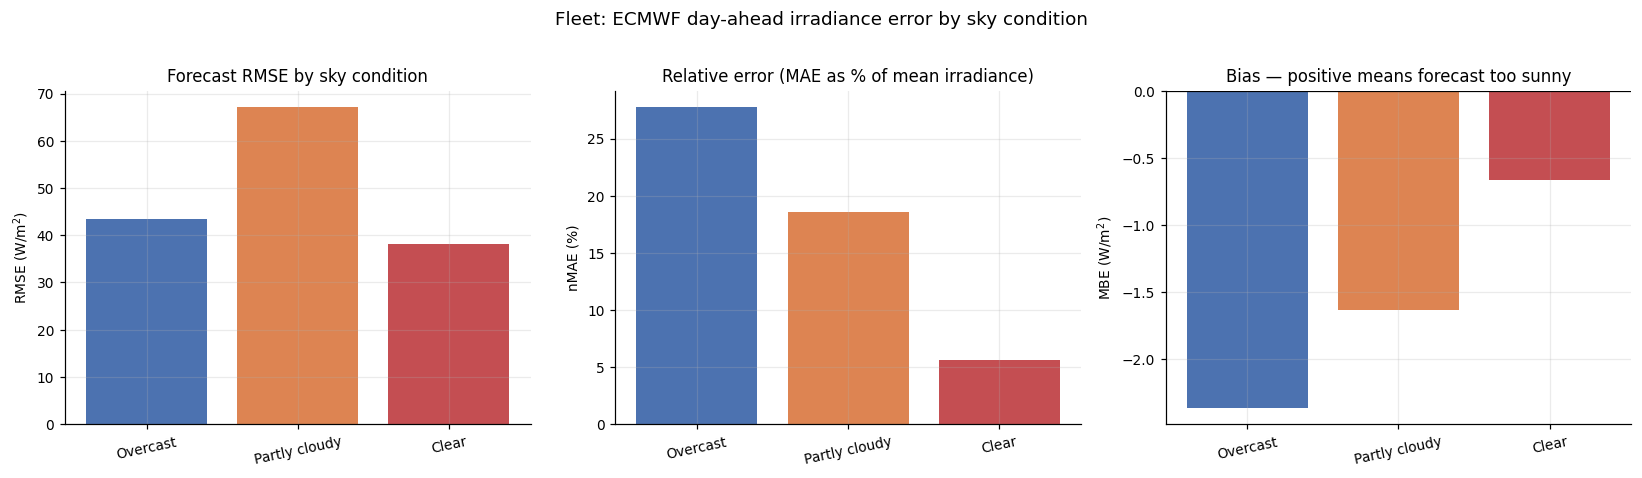

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

reg = fleet.reindex(REGIME_LABELS)
cols = [REGIME_COLORS[r] for r in reg.index]

axes[0].bar(reg.index, reg.RMSE, color=cols)
axes[0].set_title("Forecast RMSE by sky condition")
axes[0].set_ylabel("RMSE (W/m$^2$)")

axes[1].bar(reg.index, reg["nMAE_%"], color=cols)
axes[1].set_title("Relative error (MAE as % of mean irradiance)")
axes[1].set_ylabel("nMAE (%)")

axes[2].bar(reg.index, reg.MBE, color=cols)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_title("Bias — positive means forecast too sunny")
axes[2].set_ylabel("MBE (W/m$^2$)")

for ax in axes:
    ax.tick_params(axis="x", rotation=12)
fig.suptitle("Fleet: ECMWF day-ahead irradiance error by sky condition", y=1.02, fontsize=12)
fig.tight_layout()
plt.show()

## 5. Does the forecast even get the *regime* right?

Before asking "how many W/m² off", ask the blunter question: when the forecast said **clear**, was it clear?

Rows = what was forecast. Columns = what happened. Values are row-normalised percentages, so each row sums to 100. The diagonal is the hit rate.

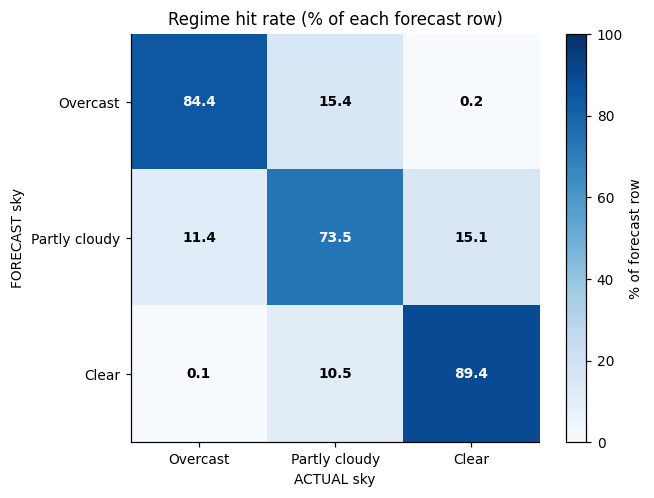

regime_act     Overcast  Partly cloudy  Clear
regime_fc                                    
Overcast           84.4           15.4    0.2
Partly cloudy      11.4           73.5   15.1
Clear               0.1           10.5   89.4

Diagonal = hit rate. Off-diagonal top-right = forecast promised sun, sky delivered cloud.


In [9]:
cm = pd.crosstab(wx.regime_fc, wx.regime_act, normalize="index") * 100
cm = cm.reindex(index=REGIME_LABELS, columns=REGIME_LABELS).round(1)

fig, ax = plt.subplots(figsize=(6, 4.6))
im = ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(3), REGIME_LABELS)
ax.set_yticks(range(3), REGIME_LABELS)
ax.set_xlabel("ACTUAL sky")
ax.set_ylabel("FORECAST sky")
ax.set_title("Regime hit rate (% of each forecast row)")
for i in range(3):
    for j in range(3):
        v = cm.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center",
                color="white" if v > 55 else "black", fontweight="bold")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of forecast row")
fig.tight_layout()
plt.show()

print(cm.to_string())
print("\nDiagonal = hit rate. Off-diagonal top-right = forecast promised sun, sky delivered cloud.")

## 6. Cloud-cover bias

`mos_training_data.csv` also carries forecast and actual **cloud cover %**, an independent view of the same failure.

mean ACTUAL cloud cover   : 66.1 %
mean FORECAST cloud cover : 51.8 %
bias                      : -14.3 pp   (negative = forecast under-reports cloud)


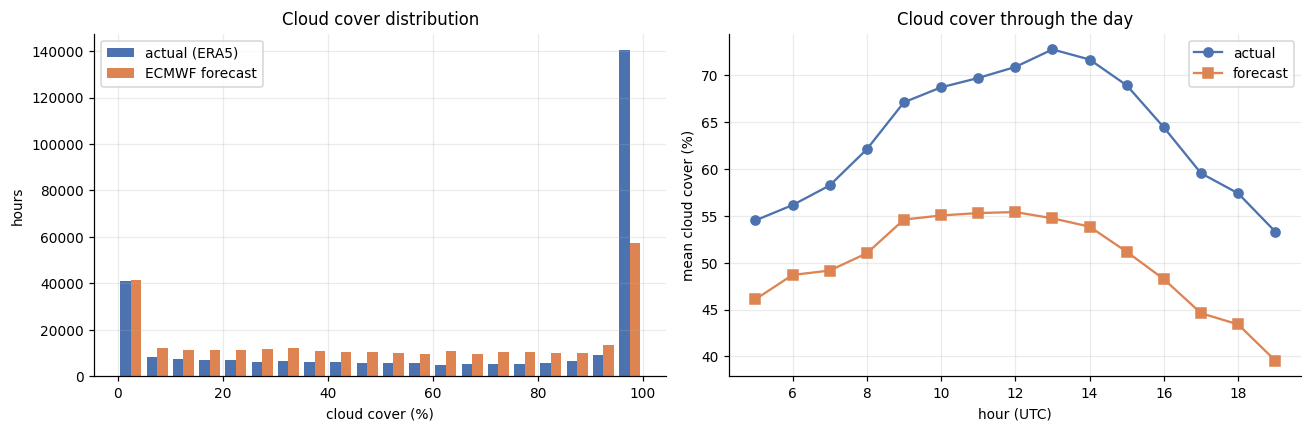

In [10]:
if {"actual_cloud", "ecmwf_cloud"}.issubset(wx.columns):
    cl = wx.dropna(subset=["actual_cloud", "ecmwf_cloud"])
    print(f"mean ACTUAL cloud cover   : {cl.actual_cloud.mean():.1f} %")
    print(f"mean FORECAST cloud cover : {cl.ecmwf_cloud.mean():.1f} %")
    print(f"bias                      : {cl.ecmwf_cloud.mean() - cl.actual_cloud.mean():+.1f} pp"
          "   (negative = forecast under-reports cloud)")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist([cl.actual_cloud, cl.ecmwf_cloud], bins=20,
                 label=["actual (ERA5)", "ECMWF forecast"], color=["#4C72B0", "#DD8452"])
    axes[0].set_xlabel("cloud cover (%)"); axes[0].set_ylabel("hours")
    axes[0].set_title("Cloud cover distribution"); axes[0].legend()

    by_h = cl.groupby("hour")[["actual_cloud", "ecmwf_cloud"]].mean()
    axes[1].plot(by_h.index, by_h.actual_cloud, "o-", label="actual", color="#4C72B0")
    axes[1].plot(by_h.index, by_h.ecmwf_cloud, "s-", label="forecast", color="#DD8452")
    axes[1].set_xlabel("hour (UTC)"); axes[1].set_ylabel("mean cloud cover (%)")
    axes[1].set_title("Cloud cover through the day"); axes[1].legend()
    fig.tight_layout(); plt.show()

## 7. Per-house figures — the main output

Six panels per rooftop:

1. **Forecast vs actual scatter**, coloured by forecast regime, with the 1:1 line. Points below the line = forecast too sunny.
2. **Error distribution by regime** (box plot). Box = middle 50%, line = median, whiskers = 5th–95th percentile.
3. **RMSE and MAE by regime**, absolute W/m².
4. **Relative error by regime** — same errors as % of that regime's mean irradiance. Often reverses the story in panel 3.
5. **Error through the day** by regime — median with an inter-quartile band.
6. **Monthly RMSE by regime** — seasonal behaviour.

In [11]:
def plot_system(sid, df, save=True, show=False):
    g = df[df.system_id == sid]
    if len(g) < 200:
        print(f"  {sid}: only {len(g)} rows, skipped")
        return None

    m = g.groupby("regime_fc", observed=True).apply(metrics).reindex(REGIME_LABELS)
    fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))

    # 1 - scatter
    ax = axes[0, 0]
    for r in REGIME_LABELS:
        s = g[g.regime_fc == r]
        ax.scatter(s.actual_ghi, s.ecmwf_ghi, s=3, alpha=0.25,
                   c=REGIME_COLORS[r], label=f"{r} (n={len(s):,})")
    hi = max(g.actual_ghi.max(), g.ecmwf_ghi.max()) * 1.05
    ax.plot([0, hi], [0, hi], "k--", lw=1, label="perfect (1:1)")
    ax.set_xlabel("actual GHI (W/m$^2$)"); ax.set_ylabel("forecast GHI (W/m$^2$)")
    ax.set_title("Forecast vs actual")
    ax.legend(fontsize=7, markerscale=3, loc="upper left")

    # 2 - error distribution
    ax = axes[0, 1]
    data = [g[g.regime_fc == r].err.dropna() for r in REGIME_LABELS]
    bp = ax.boxplot(data, labels=REGIME_LABELS, patch_artist=True,
                    whis=(5, 95), showfliers=False)
    for patch, r in zip(bp["boxes"], REGIME_LABELS):
        patch.set_facecolor(REGIME_COLORS[r]); patch.set_alpha(0.75)
    for med in bp["medians"]:
        med.set_color("black"); med.set_linewidth(1.5)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel("forecast - actual (W/m$^2$)")
    ax.set_title("Error spread  (above 0 = too sunny)")
    ax.tick_params(axis="x", rotation=12)

    # 3 - absolute error
    ax = axes[0, 2]
    x = np.arange(len(REGIME_LABELS)); w = 0.38
    ax.bar(x - w / 2, m.RMSE, w, label="RMSE", color="#55A868")
    ax.bar(x + w / 2, m.MAE, w, label="MAE", color="#8172B3")
    ax.set_xticks(x, REGIME_LABELS); ax.tick_params(axis="x", rotation=12)
    ax.set_ylabel("W/m$^2$"); ax.set_title("Absolute error"); ax.legend(fontsize=8)

    # 4 - relative error
    ax = axes[1, 0]
    ax.bar(REGIME_LABELS, m["nMAE_%"], color=[REGIME_COLORS[r] for r in REGIME_LABELS])
    ax.set_ylabel("MAE as % of mean irradiance")
    ax.set_title("Relative error  (fair across bright and dim skies)")
    ax.tick_params(axis="x", rotation=12)

    # 5 - diurnal
    ax = axes[1, 1]
    for r in REGIME_LABELS:
        s = g[g.regime_fc == r]
        if len(s) < 30:
            continue
        q = s.groupby("hour").err.quantile([0.25, 0.5, 0.75]).unstack()
        ax.plot(q.index, q[0.5], "o-", ms=3, color=REGIME_COLORS[r], label=r)
        ax.fill_between(q.index, q[0.25], q[0.75], color=REGIME_COLORS[r], alpha=0.18)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("hour (UTC)"); ax.set_ylabel("error (W/m$^2$)")
    ax.set_title("Error through the day (median + IQR)"); ax.legend(fontsize=7)

    # 6 - monthly
    ax = axes[1, 2]
    for r in REGIME_LABELS:
        s = g[g.regime_fc == r]
        if len(s) < 30:
            continue
        mo = s.groupby("month").apply(
            lambda d: np.sqrt(((d.ecmwf_ghi - d.actual_ghi) ** 2).mean()))
        ax.plot(range(len(mo)), mo.values, "o-", ms=3,
                color=REGIME_COLORS[r], label=r)
    months = sorted(g.month.unique())
    step = max(1, len(months) // 8)
    ax.set_xticks(range(0, len(months), step), months[::step], rotation=45, fontsize=7)
    ax.set_ylabel("RMSE (W/m$^2$)"); ax.set_title("Seasonal RMSE"); ax.legend(fontsize=7)

    cap = float(meta.set_index("system_id").loc[sid, "capacity_kwp"]) \
        if sid in meta.system_id.values else float("nan")
    fig.suptitle(
        f"System {sid}  ({cap:.2f} kWp)   ECMWF day-ahead irradiance error by sky condition"
        f"   |   n={len(g):,} daylight hours", fontsize=12, y=1.0)
    fig.tight_layout()

    if save:
        fig.savefig(OUT / f"{sid}.png", bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    return m

In [ ]:
# one worked example, rendered inline
example_sid = sorted(wx.system_id.unique())[0]
m = plot_system(example_sid, wx, save=True, show=True)
print(f"\nSystem {example_sid} — metrics by forecast regime\n")
print(m.round(2).to_string())

In [ ]:
# every house -> reports/weather_error/<sid>.png
rows = []
for sid in sorted(wx.system_id.unique()):
    m = plot_system(sid, wx, save=True, show=False)
    if m is None:
        continue
    m = m.reset_index().rename(columns={"index": "regime", "regime_fc": "regime"})
    m.insert(0, "system_id", sid)
    rows.append(m)
    print(f"  {sid} done")

summary = pd.concat(rows, ignore_index=True)
summary.to_csv(OUT / "summary_by_system_regime.csv", index=False)
print(f"\nWrote {OUT / 'summary_by_system_regime.csv'}  ({len(summary)} rows)")
print(f"Figures in {OUT}")

## 7b. Cross-house comparison

Is the weather error a property of the *weather* or of the *house*? If all houses show the same error, the limitation is the ECMWF grid and no rooftop-specific fix exists.

In [ ]:
piv = summary.pivot(index="system_id", columns="regime", values="RMSE")[REGIME_LABELS]
piv = piv.sort_values("Partly cloudy")

fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(piv)); w = 0.27
for i, r in enumerate(REGIME_LABELS):
    ax.bar(x + (i - 1) * w, piv[r], w, label=r, color=REGIME_COLORS[r])
ax.set_xticks(x, piv.index, rotation=90, fontsize=7)
ax.set_ylabel("forecast RMSE (W/m$^2$)"); ax.set_xlabel("system_id")
ax.set_title("Irradiance forecast error per house, by sky condition")
ax.legend()
fig.tight_layout(); fig.savefig(OUT / "_all_houses_rmse.png", bbox_inches="tight"); plt.show()

print("spread across houses (W/m^2):")
print(piv.agg(["min", "median", "max", "std"]).round(1).to_string())
print("\nA small std relative to the median means the error belongs to the WEATHER MODEL,")
print("not to any individual rooftop - so no per-house fix can remove it.")

## 8. Independent cross-check — the panels as pyranometers

Everything above scores ECMWF against **ERA5**, which is an ECMWF product. Shared physics inflates the agreement.

Here the PV panels supply independent ground truth. A rooftop's own output is a real physical measurement of the light that actually arrived. Define a **PV-derived clear-sky index**:

$$K_t^{\text{PV}} = \frac{\text{target\_norm}}{\text{clearsky\_ghi}/1000}$$

and compare it with the forecast `clearsky_index_fc`. Units differ from the ERA5 comparison, so read the **shape** — if error still peaks in partly-cloudy conditions here, the conclusion is real and not an artefact of ERA5.

Panel efficiency, temperature and shading add noise, so absolute values are not comparable to section 4.

In [ ]:
src = C.MODEL_READY_V3 if C.MODEL_READY_V3.exists() else C.PARENT_MODEL_READY
pv = pd.read_csv(src, usecols=["system_id", "timestamp", "target_norm", "clearsky_ghi",
                               "clearsky_index_fc", "is_daylight", "sun_elevation"])
pv = pv[(pv.is_daylight == True) & (pv.sun_elevation > 5)]
pv = pv[~pv.system_id.isin(C.EXCLUDE_SYSTEMS)]
pv = pv[pv.clearsky_ghi > 50]

pv["kt_pv"] = (pv.target_norm / (pv.clearsky_ghi / 1000.0)).clip(0, 1.5)
pv["kt_err_pv"] = pv.clearsky_index_fc - pv.kt_pv
pv["regime_fc"] = pd.cut(pv.clearsky_index_fc, REGIME_BINS, labels=REGIME_LABELS)

cross = pv.groupby("regime_fc", observed=True).agg(
    n=("kt_err_pv", "size"),
    kt_MBE=("kt_err_pv", "mean"),
    kt_MAE=("kt_err_pv", lambda s: s.abs().mean()),
    kt_RMSE=("kt_err_pv", lambda s: np.sqrt((s ** 2).mean())),
).reindex(REGIME_LABELS).round(4)
print("PV-DERIVED cross-check (clear-sky index units, not W/m^2)\n")
print(cross.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(cross.index, cross.kt_RMSE, color=[REGIME_COLORS[r] for r in cross.index])
axes[0].set_ylabel("RMSE (clear-sky index)")
axes[0].set_title("PV-derived error by sky condition")
axes[0].tick_params(axis="x", rotation=12)

era = fleet.reindex(REGIME_LABELS)
axes[1].bar(np.arange(3) - 0.2, era.RMSE / era.RMSE.max(), 0.4,
            label="ERA5 comparison", color="#4C72B0")
axes[1].bar(np.arange(3) + 0.2, cross.kt_RMSE / cross.kt_RMSE.max(), 0.4,
            label="PV-derived", color="#DD8452")
axes[1].set_xticks(range(3), REGIME_LABELS)
axes[1].set_ylabel("RMSE, scaled to its own max")
axes[1].set_title("Same shape? (each series normalised)")
axes[1].legend(fontsize=8); axes[1].tick_params(axis="x", rotation=12)
fig.tight_layout(); fig.savefig(OUT / "_cross_check.png", bbox_inches="tight"); plt.show()

## 9. What to take away

Run the cell below for an auto-generated summary of what this dataset actually showed.

Points to check when reading it:

1. **Which regime has the worst *relative* error?** Absolute RMSE flatters overcast skies — barely any light means barely any error in W/m². `nMAE_%` is the fair comparison.
2. **Is the bias positive in cloudy regimes?** A positive MBE means ECMWF systematically over-predicts sunshine when it is cloudy — consistent with the fleet's cloud-cover under-reporting in section 6.
3. **Do all houses look alike (section 7b)?** If the spread across houses is small next to the median, the error belongs to the weather model, not any rooftop — and no per-house correction can remove it.
4. **Does the PV cross-check keep the same shape (section 8)?** If yes, the pattern survives independent ground truth and is safe to report.

**Remember the caveat in the header:** ERA5 shares physics with the IFS forecast being scored, so section 4-7 errors are a lower bound on true forecast error. Say so whenever quoting them.

In [ ]:
f = fleet.reindex(REGIME_LABELS)
worst_rel = f["nMAE_%"].idxmax()
worst_abs = f.RMSE.idxmax()
spread = piv.std() / piv.median()

print("=" * 70)
print("AUTO-SUMMARY")
print("=" * 70)
print(f"Systems: {wx.system_id.nunique()}   daylight hours: {len(wx):,}")
print(f"Window : {wx.timestamp.min():%Y-%m-%d} -> {wx.timestamp.max():%Y-%m-%d}\n")
for r in REGIME_LABELS:
    row = f.loc[r]
    print(f"{r:15s} n={int(row.n):7,}  RMSE={row.RMSE:6.1f} W/m2  "
          f"nMAE={row['nMAE_%']:5.1f}%  bias={row.MBE:+6.1f} W/m2")
print(f"\nWorst ABSOLUTE error : {worst_abs}")
print(f"Worst RELATIVE error : {worst_rel}   <- the honest answer")
print("\nSpread across houses (std / median of RMSE):")
for r in REGIME_LABELS:
    print(f"  {r:15s} {spread[r]:.3f}")
print("\nSmall values above mean every rooftop sees essentially the same")
print("forecast error, i.e. it is a property of the weather model.")
print("\nCAVEAT: ground truth is ERA5, an ECMWF reanalysis. Shared physics with")
print("the IFS forecast inflates agreement. These are a LOWER BOUND on real error.")